In [47]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

## Simple Linear Regression from scratch using OLS

In [25]:
class SimpleLinearRegressionOLS:

    def __init__(self):
        self.coef_ = None
        self.intercept_ = None
    
    def fit(self, X: np.ndarray, y: np.ndarray):

        if X.ndim != 1 or y.ndim != 1:
            raise ValueError("X and y must be one-dimensional arrays.")
        
        if X.shape[0] != y.shape[0]:
            raise  ValueError("X and y must have the same number of samples.")
        
        x_mean = X.mean()
        y_mean = y.mean()

        numerator = np.sum((X - x_mean) * (y - y_mean))
        denominator = np.sum((X - x_mean)**2)

        if denominator == 0:
            raise ValueError("X must have non-zero variance.")
        
        self.coef_ = numerator / denominator
        self.intercept_ = y_mean - (self.coef_ * x_mean)

    def predict(self, X: np.ndarray):
        
        if self.coef_ is None or self.intercept_ is None:
            raise ValueError("Fit the model before making predictions.")
        
        return self.coef_ * X + self.intercept_

In [26]:
# Generate dummy data

X, y = make_regression(
    n_samples=200,
    n_features=1,
    noise=20,
    random_state=42
)

In [27]:
X[:10]

array([[ 1.85227818],
       [ 0.47359243],
       [-1.23086432],
       [ 0.62566735],
       [-0.07201012],
       [ 0.81252582],
       [-0.18565898],
       [-0.81581028],
       [ 0.06023021],
       [ 0.65655361]])

In [28]:
y[:10]

array([ 1.37096464e+02,  5.90025564e+01, -7.65920750e+01,  6.08039188e+01,
       -8.88621709e+00,  1.02150181e+02, -1.83915888e+01, -6.43274684e+01,
       -1.36372814e-01,  9.48035858e+01])

In [29]:
X.shape, y.shape

((200, 1), (200,))

In [30]:
# Convert X from shape (200, 1) to (200,)

X = X.ravel()

In [31]:
X.shape

(200,)

In [32]:
# Split the data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [33]:
len(X_train), len(X_test)

(160, 40)

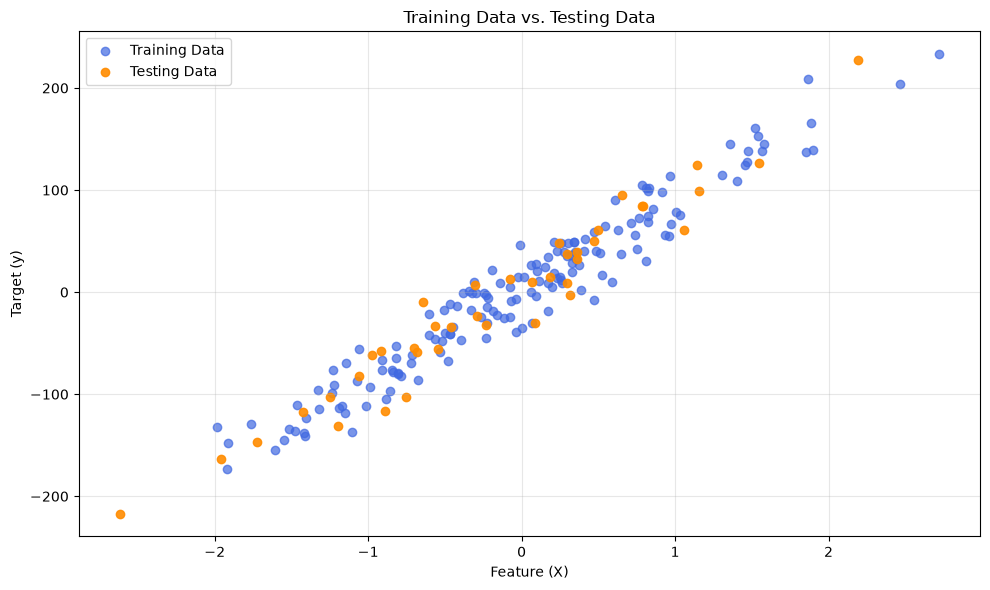

In [34]:
# Visualize the train-test split

plt.figure(figsize=(10,6))

plt.scatter(X_train, y_train, color="royalblue", alpha=0.7, label="Training Data")
plt.scatter(X_test, y_test, color="darkorange", alpha=0.9, label="Testing Data")

plt.title("Training Data vs. Testing Data")
plt.xlabel("Feature (X)")
plt.ylabel("Target (y)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [35]:
# Train the model

lr_model = SimpleLinearRegressionOLS()

lr_model.fit(X_train, y_train)

In [36]:
print(f"Slope (coefficient): {lr_model.coef_:.4f}")
print(f"Intercept:           {lr_model.intercept_:.4f}")

Slope (coefficient): 86.5115
Intercept:           2.4461


In [37]:
print(f"Regression equation: y = {lr_model.coef_:.4f} * X + {lr_model.intercept_:.4f}")

Regression equation: y = 86.5115 * X + 2.4461


In [39]:
# Predict on the test data

y_pred = lr_model.predict(X_test)

In [40]:
y_pred[:5]

array([  70.08280437,   28.13870421, -120.81106033,    8.37759086,
        -77.09470605])

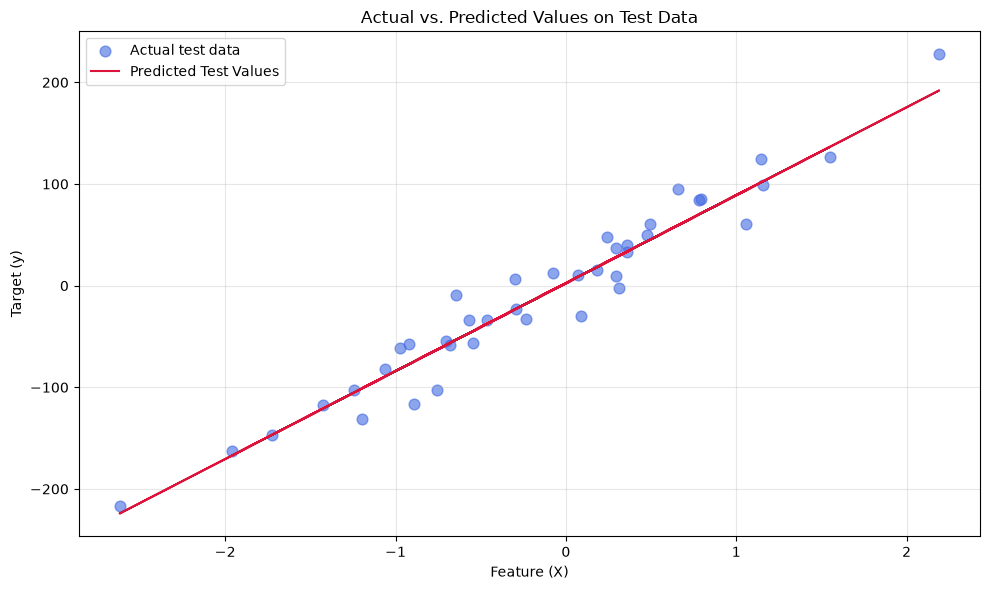

In [44]:
# Visualize actual test data vs. predictions


plt.figure(figsize=(10, 6))

plt.scatter(X_test, y_test, color="royalblue", s=60, alpha=0.6, label="Actual test data")
plt.plot(X_test, y_pred, color="crimson", label="Predicted Test Values")

plt.title("Actual vs. Predicted Values on Test Data")
plt.xlabel("Feature (X)")
plt.ylabel("Target (y)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [48]:
# Evaluate model performance

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

In [49]:
print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

MAE:  16.0405
MSE:  437.5499
RMSE: 20.9177
R²:   0.9450
